# 🏗️ Building Age Classification from Satellite Imagery

# Notebook 6 — Stage 1 Model, Few-Shot Transfer & Evaluation

---

This notebook delivers the four items required in Notebook 1, Section 1.5:

1. **Stage 1 model** trained on Madrid, with repeated cross-validation (mean ± std macro F1, confusion-matrix proportions).
2. **A transfer procedure** — `adapt_to_city(...)` — that turns the Stage 1 model into an Amsterdam model from *n* labelled
   pixels per class. It is parameterised by `n` and fully seeded.
3. **Cross-validated Amsterdam scores** for *n* = 5, 25, 50, 100, 200 labelled pixels per class.
4. A table and an **F1 vs. log2(n)** plot with error bars, plus the saved model and result files.

### Approach in one paragraph

Features from Notebook 5 are **standardised separately per city** (no labels needed), so a value means "how unusual is
this pixel *for its city*". A **LightGBM** gradient-boosted model is trained on Madrid with class-balanced weights.
To adapt to a new city we treat the Madrid model as a **prior** and correct it with the few local labels, using three
complementary learners that are averaged: (i) **continued boosting** — new shallow trees grown on top of the Madrid model's
log-odds, (ii) a **regularised logistic "stacker"** on the Madrid probabilities plus the 40 most important features, and
(iii) **class prototypes** (Notebook 4's metric-learning idea) whose weight fades as more labels arrive. Spatial smoothing of the predicted probabilities was also evaluated, but
Madrid cross-validation rejected it (Section 6.4): the spatial *features* already carry the neighbourhood context.

## 6.1 Setup & Configuration

In [1]:
import json, os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.ndimage import uniform_filter
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix, classification_report

# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_DIR  = Path('data') if Path('data/features').exists() else Path('../data')
FEAT_DIR  = DATA_DIR / 'features'
MODEL_DIR = Path('models');  MODEL_DIR.mkdir(exist_ok=True)
OUT_DIR   = Path('results'); OUT_DIR.mkdir(exist_ok=True)

# ── Configuration (change here only) ──────────────────────────────────────────
SEED              = 42                       # every random step below derives from this
N_FOLDS, N_REPEATS = 5, 5                    # Madrid CV: 25 fits (Notebook 4 recommends repeats for reliable std)
SHOTS_PER_CLASS   = [5, 25, 50, 100, 200]    # the five Amsterdam label budgets required by the challenge
AMS_FOLDS, AMS_REPEATS = 5, 2                # Amsterdam CV: 10 scores per budget
FEATURE_GROUPS    = ['baseline', 'anomaly', 'change', 'meta', 'spatial_v1', 'spatial']

# Quick smoke-test mode (set the environment variable H4D_QUICK=1). Fewer folds and trees, so the whole
# notebook runs in a few minutes to check the code end to end. The reported numbers come from QUICK_RUN = False.
QUICK_RUN = os.environ.get('H4D_QUICK', '0') == '1'
if QUICK_RUN:
    N_FOLDS, N_REPEATS, AMS_FOLDS, AMS_REPEATS = 3, 1, 3, 1
    print('QUICK_RUN: reduced folds and trees - numbers are NOT the reported results')

CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
CLASS_LABELS_MADRID    = {1: 'Pre-1960', 2: '1960-1984', 3: '1984-2004', 4: '2004-2024'}
CLASS_LABELS_AMSTERDAM = {1: 'Pre-1945', 2: '1945-1984', 3: '1984-2004', 4: '2004-2024'}

# Notebook 4 baseline numbers, for comparison in tables and plots
BASELINE_NB4 = {'madrid': (0.6180, 0.005), 'zero_shot': 0.3427,
                5: (0.5437, 0.0324), 25: (0.5986, 0.0176), 50: (0.6079, 0.0101),
                100: (0.6129, 0.0097), 200: (0.6150, 0.0036)}

plt.rcParams['figure.dpi'] = 100
print(f'LightGBM {lgb.__version__}; data from {FEAT_DIR.resolve()}')

LightGBM 4.7.0; data from /home/claude/h4d/data/features


---

## 6.2 Load Features & Per-City Standardisation

**DECISION — standardise each city with its own statistics.** Notebook 3 fit a `StandardScaler` on Madrid and applied it to
Amsterdam. That keeps Madrid's scale: an Amsterdam pixel that is perfectly ordinary *for Amsterdam* can look extreme in Madrid
units, and the model then reads city differences as age differences. Standardising each city by its **own median and IQR**
(robust to outliers, uses no labels) aligns the two feature distributions — the same idea as AdaBN / per-domain
batch-norm in deep domain adaptation. Measured effect (exp1): zero-shot F1 0.432 → 0.450, 25-shot 0.524 → 0.549, Madrid unchanged.

In [2]:
groups = json.load(open(FEAT_DIR / 'feature_groups.json'))
FEATURE_COLS = [c for g in FEATURE_GROUPS for c in groups[g]]

df_mad = pd.read_parquet(FEAT_DIR / 'features_madrid.parquet')
df_ams = pd.read_parquet(FEAT_DIR / 'features_amsterdam.parquet')

def city_standardise(X):
    # robust z-score using the city's own pixels; clip extreme values so a few outliers cannot dominate
    X   = np.asarray(X, np.float32)
    med = np.median(X, 0)
    iqr = np.percentile(X, 75, 0) - np.percentile(X, 25, 0)
    iqr = np.where(iqr < 1e-6, X.std(0) + 1e-6, iqr)      # binary / near-constant columns
    return np.clip((X - med) / iqr, -10, 10).astype(np.float32)

X_madrid,    y_madrid    = city_standardise(df_mad[FEATURE_COLS].values), df_mad['age_class'].values.astype(int)
X_amsterdam, y_amsterdam = city_standardise(df_ams[FEATURE_COLS].values), df_ams['age_class'].values.astype(int)
pix_mad = df_mad[['px_key', 'py_key']].values
pix_ams = df_ams[['px_key', 'py_key']].values

print(f'Features: {len(FEATURE_COLS)}  (' + ', '.join(f'{g}={len(groups[g])}' for g in FEATURE_GROUPS) + ')')
for name, y, lbl in [('Madrid', y_madrid, CLASS_LABELS_MADRID), ('Amsterdam', y_amsterdam, CLASS_LABELS_AMSTERDAM)]:
    print(f'{name:10s}: {len(y):,} pixels | ' +
          ' | '.join(f'C{c} {lbl[c]}: {(y == c).mean():.1%}' for c in (1, 2, 3, 4)))

# ── Helpers used for reports and maps further down ────────────────────────────
def report_table(y_true, y_pred, labels):
    '''sklearn classification_report as a DataFrame (precision, recall, F1, support per class + averages).'''
    r = classification_report(y_true, y_pred, labels=[1, 2, 3, 4], output_dict=True, zero_division=0)
    t = pd.DataFrame(r).T
    t.index = [f'C{i} {labels[int(i)]}' if i in '1234' else i for i in t.index]
    t.loc['accuracy', ['precision', 'recall']] = np.nan            # accuracy is a single number: show it once
    t.loc['accuracy', 'support'] = t.loc['macro avg', 'support']
    t['support'] = t['support'].astype(int)
    return t

def to_grid(pix, values):
    '''Place one value per pixel on the 30 m grid -> 2-D array for maps (north up with origin='lower').'''
    x = (pix[:, 0] - pix[:, 0].min()).astype(int); y = (pix[:, 1] - pix[:, 1].min()).astype(int)
    g = np.full((y.max() + 1, x.max() + 1), np.nan, np.float32); g[y, x] = values
    return g

Features: 284  (baseline=60, anomaly=99, change=17, meta=3, spatial_v1=20, spatial=85)
Madrid    : 76,263 pixels | C1 Pre-1960: 18.1% | C2 1960-1984: 35.6% | C3 1984-2004: 24.5% | C4 2004-2024: 21.8%
Amsterdam : 25,992 pixels | C1 Pre-1945: 29.1% | C2 1945-1984: 33.9% | C3 1984-2004: 26.0% | C4 2004-2024: 11.1%


---

## 6.3 Stage 1 Model: LightGBM

**Why LightGBM instead of Random Forest?** Gradient boosting fits the hard examples sequentially and usually beats a random
forest on tabular data. With identical (baseline) features it already lifted Madrid 3-fold CV from 0.62 (RF, Notebook 4) to
0.647 (exp1). It also supports **continued training from a starting score**, which is the core of our transfer step (Section 6.7).

Hyper-parameters (each one explained):

In [3]:
STAGE1_PARAMS = dict(
    n_estimators      = 700,        # with lr 0.05: enough rounds to converge; more gave no CV gain
    learning_rate     = 0.05,       # small steps generalise better than few large ones
    num_leaves        = 63,         # moderately deep trees: enough for feature interactions, not memorisation
    min_child_samples = 40,         # each leaf needs 40 pixels -> stops trees fitting single-pixel noise
    subsample         = 0.8, subsample_freq=1,   # row bagging: decorrelates trees (like a random forest)
    colsample_bytree  = 0.5,        # many features are correlated; sampling half per tree adds diversity
    reg_lambda        = 1.0,        # mild L2 on leaf values
    class_weight      = 'balanced', # DECISION: Notebook 4 showed class 2 (largest) is over-predicted;
                                    # balanced weights equalise the classes, which is what macro F1 rewards
    random_state      = SEED, n_jobs=-1, verbose=-1)
if QUICK_RUN:
    STAGE1_PARAMS['n_estimators'] = 80

### Spatial smoothing of predictions

**DECISION.** Notebook 4 (Section 4.3a) noted that the probability maps already identify the right *districts*, and suggested a
second step acting on the probability image. We blend each pixel's probabilities with the mean prediction of the building
pixels within radius *r*:

$$p^{\text{smooth}}_i = (1-\alpha)\,p_i + \alpha \cdot \operatorname{mean}_{j \in \mathcal{N}_r(i)} p_j$$

Only **predictions** are averaged, never labels. To keep the Madrid CV honest, only pixels of the **same held-out fold** are
used as neighbours (their predictions are out-of-sample). α and *r* are chosen on Madrid and then **frozen** for Amsterdam.

In [4]:
def smooth_proba(pix, proba, alpha=0.5, r=3, neighbour_mask=None):
    if alpha <= 0:
        return proba
    x = (pix[:, 0] - pix[:, 0].min()).astype(int); y = (pix[:, 1] - pix[:, 1].min()).astype(int)
    H, W = y.max() + 1, x.max() + 1
    m = np.ones(len(pix), bool) if neighbour_mask is None else neighbour_mask
    s = 2 * r + 1
    occ = np.zeros((H, W), np.float32); occ[y[m], x[m]] = 1
    cnt = uniform_filter(occ, s, mode='constant')[y, x] * s * s - m      # neighbours, excluding self
    nb  = np.empty_like(proba)
    for c in range(proba.shape[1]):
        g = np.zeros((H, W), np.float32); g[y[m], x[m]] = proba[m, c]
        tot = uniform_filter(g, s, mode='constant')[y, x] * s * s - proba[:, c] * m
        nb[:, c] = tot / np.maximum(cnt, 1)
    out = (1 - alpha) * proba + alpha * nb
    out[cnt <= 0] = proba[cnt <= 0]                                       # isolated pixels keep their own prediction
    return out / out.sum(1, keepdims=True)

SMOOTH_GRID = [(0.0, 0), (0.3, 3), (0.5, 3), (0.7, 3), (0.5, 6), (0.7, 6)]

---

## 6.4 Cross-Validation on Madrid

Same protocol as Notebook 4: `RepeatedStratifiedKFold` with 5 folds × 5 repeats = 25 fits; we report the mean and std of
the 25 macro F1 scores, and the out-of-fold confusion matrix accumulated over all fits. Each fit takes ~2 minutes on a
2-core machine.

In [5]:
rskf  = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED)
total = N_FOLDS * N_REPEATS
cv_f1 = {k: [] for k in SMOOTH_GRID}
oof   = {k: ([], []) for k in SMOOTH_GRID}        # (y_true, y_pred) accumulated over all fits
oof1_proba = np.zeros((len(y_madrid), 4), np.float32)   # repeat 1: every pixel predicted exactly once -> maps

print(f'{N_FOLDS}-fold x {N_REPEATS}-repeat CV on Madrid  ({total} model fits)')
print('-' * 72)
t0 = time.time()
for fit_num, (tr, va) in enumerate(rskf.split(X_madrid, y_madrid), 1):
    model = lgb.LGBMClassifier(**STAGE1_PARAMS).fit(X_madrid[tr], y_madrid[tr])
    p_va  = model.predict_proba(X_madrid[va])
    if fit_num <= N_FOLDS:
        oof1_proba[va] = p_va
    for (a, r) in SMOOTH_GRID:
        # neighbours restricted to the held-out fold -> only out-of-sample predictions are averaged
        p = smooth_proba(pix_mad[va], p_va, a, r)
        pred = model.classes_[p.argmax(1)]
        cv_f1[(a, r)].append(f1_score(y_madrid[va], pred, average='macro'))
        oof[(a, r)][0].extend(y_madrid[va]); oof[(a, r)][1].extend(pred)
    print(f'  Fit {fit_num:3d}/{total}: macro-F1 = {cv_f1[(0.0, 0)][-1]:.4f} (raw)   '
          f'{cv_f1[(0.5, 3)][-1]:.4f} (smoothed a=0.5,r=3)   [{time.time()-t0:.0f}s]')
print('-' * 72)
for k in SMOOTH_GRID:
    print(f'  alpha={k[0]:.1f}, r={k[1]}:  mean macro F1 = {np.mean(cv_f1[k]):.4f} +/- {np.std(cv_f1[k]):.4f}')

SMOOTH_ALPHA, SMOOTH_R = max(SMOOTH_GRID, key=lambda k: np.mean(cv_f1[k]))
print(f'\nSelected smoothing (frozen for Amsterdam): alpha={SMOOTH_ALPHA}, r={SMOOTH_R}')

5-fold x 5-repeat CV on Madrid  (25 model fits)
------------------------------------------------------------------------


  Fit   1/25: macro-F1 = 0.7851 (raw)   0.7713 (smoothed a=0.5,r=3)   [82s]


  Fit   2/25: macro-F1 = 0.7871 (raw)   0.7722 (smoothed a=0.5,r=3)   [181s]


  Fit   3/25: macro-F1 = 0.7891 (raw)   0.7729 (smoothed a=0.5,r=3)   [266s]


  Fit   4/25: macro-F1 = 0.7745 (raw)   0.7617 (smoothed a=0.5,r=3)   [347s]


  Fit   5/25: macro-F1 = 0.7793 (raw)   0.7667 (smoothed a=0.5,r=3)   [431s]


... (16 outputs left out)

  Fit  22/25: macro-F1 = 0.7827 (raw)   0.7671 (smoothed a=0.5,r=3)   [1857s]


  Fit  23/25: macro-F1 = 0.7878 (raw)   0.7721 (smoothed a=0.5,r=3)   [1938s]


  Fit  24/25: macro-F1 = 0.7812 (raw)   0.7703 (smoothed a=0.5,r=3)   [2019s]


  Fit  25/25: macro-F1 = 0.7839 (raw)   0.7715 (smoothed a=0.5,r=3)   [2102s]
------------------------------------------------------------------------
  alpha=0.0, r=0:  mean macro F1 = 0.7832 +/- 0.0035
  alpha=0.3, r=3:  mean macro F1 = 0.7814 +/- 0.0033
  alpha=0.5, r=3:  mean macro F1 = 0.7698 +/- 0.0030
  alpha=0.7, r=3:  mean macro F1 = 0.7456 +/- 0.0033
  alpha=0.5, r=6:  mean macro F1 = 0.7678 +/- 0.0029
  alpha=0.7, r=6:  mean macro F1 = 0.7343 +/- 0.0034

Selected smoothing (frozen for Amsterdam): alpha=0.0, r=0


> **Note on smoothing in Madrid CV.** Because only the held-out fold (20 % of pixels) can serve as neighbours, Madrid
> pixels see far fewer neighbours than they will at deployment. The smoothed Madrid score is therefore a *conservative*
> estimate of the smoothing benefit.
>
> **Result:** every setting *lowered* Madrid CV (α = 0.3, r = 3: −0.002; α = 0.5, r = 3: −0.013; α = 0.7, r = 6: −0.049),
> so **α = 0 (no smoothing)** is selected and frozen. The spatial features of Notebook 5 already give each pixel its
> neighbourhood context, so averaging neighbours' predictions as well mostly blurs real boundaries between estates.

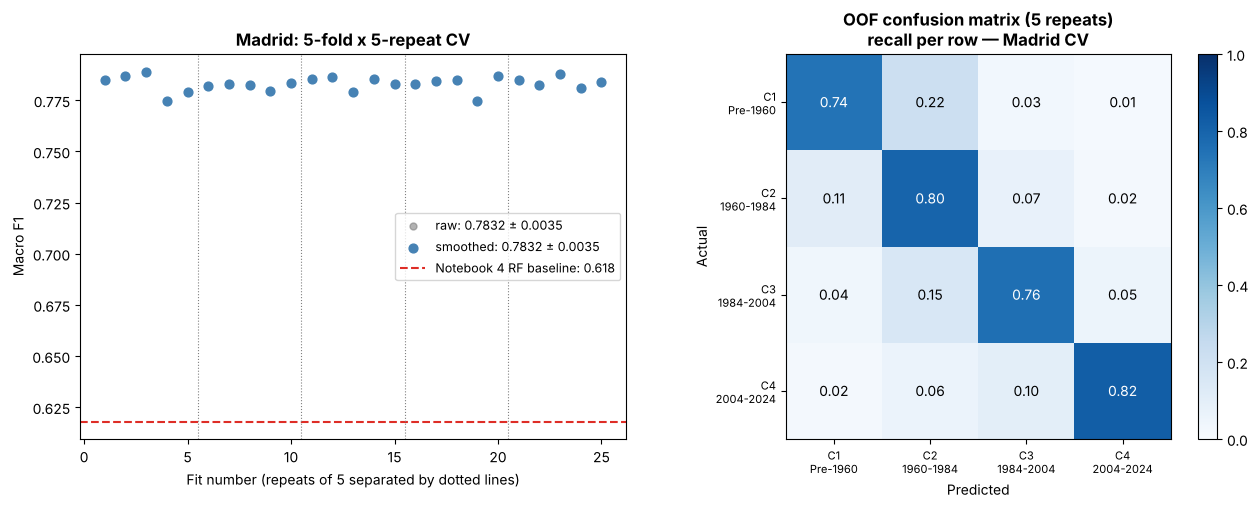

Madrid out-of-fold classification report (5-fold x 5-repeat, every pixel scored 5x):


,precision,recall,f1-score,support
C1 Pre-1960,0.7191,0.7417,0.7302,"68,970"
C2 1960-1984,0.7598,0.7988,0.7788,"135,760"
C3 1984-2004,0.7802,0.7570,0.7684,"93,360"
C4 2004-2024,0.8905,0.8225,0.8551,"83,225"
accuracy,,,0.7834,"381,315"
macro avg,0.7874,0.7800,0.7832,"381,315"
weighted avg,0.7860,0.7834,0.7841,"381,315"


In [6]:
best = (SMOOTH_ALPHA, SMOOTH_R)
madrid_f1_mean, madrid_f1_std = float(np.mean(cv_f1[best])), float(np.std(cv_f1[best]))
raw_f1_mean, raw_f1_std       = float(np.mean(cv_f1[(0.0, 0)])), float(np.std(cv_f1[(0.0, 0)]))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
xs = np.arange(1, total + 1)
ax.scatter(xs, cv_f1[(0.0, 0)], color='grey', s=25, alpha=0.6, label=f'raw: {raw_f1_mean:.4f} ± {raw_f1_std:.4f}')
ax.scatter(xs, cv_f1[best], color='steelblue', s=40, zorder=3, label=f'smoothed: {madrid_f1_mean:.4f} ± {madrid_f1_std:.4f}')
ax.axhline(BASELINE_NB4['madrid'][0], color='#de2d26', ls='--', label=f'Notebook 4 RF baseline: {BASELINE_NB4["madrid"][0]:.3f}')
for r in range(1, N_REPEATS):
    ax.axvline(r * N_FOLDS + 0.5, color='grey', lw=0.8, ls=':')
ax.set_xlabel(f'Fit number (repeats of {N_FOLDS} separated by dotted lines)'); ax.set_ylabel('Macro F1')
ax.set_title(f'Madrid: {N_FOLDS}-fold x {N_REPEATS}-repeat CV', fontweight='bold'); ax.legend(fontsize=9)

ax = axes[1]
cm = confusion_matrix(oof[best][0], oof[best][1], labels=[1, 2, 3, 4])
cm_madrid = cm / cm.sum(1, keepdims=True)
xl = [f'C{c}\n{CLASS_LABELS_MADRID[c]}' for c in (1, 2, 3, 4)]
im = ax.imshow(cm_madrid, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(xl, fontsize=8); ax.set_yticks(range(4)); ax.set_yticklabels(xl, fontsize=8)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{cm_madrid[i, j]:.2f}', ha='center', va='center', color='white' if cm_madrid[i, j] > 0.6 else 'black')
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); plt.colorbar(im, ax=ax)
ax.set_title(f'OOF confusion matrix ({N_REPEATS} repeats)\nrecall per row — Madrid CV', fontweight='bold')
plt.tight_layout(); plt.savefig(OUT_DIR / 'madrid_cv.png', bbox_inches='tight'); plt.show()

# Classification report — pooled over all out-of-fold predictions of the improved Stage 1 model
print(f'Madrid out-of-fold classification report ({N_FOLDS}-fold x {N_REPEATS}-repeat, every pixel scored {N_REPEATS}x):')
rep_madrid = report_table(oof[best][0], oof[best][1], CLASS_LABELS_MADRID)
display(rep_madrid.style.format({'precision': '{:.4f}', 'recall': '{:.4f}', 'f1-score': '{:.4f}', 'support': '{:,}'}, na_rep=''))

---

## 6.5 Final Stage 1 Model: Train on All Madrid Data

The final model is trained on every Madrid pixel and saved — this is **deliverable 1**. The feature list and the parameters
are saved next to it so the model can be reloaded and applied to any city processed by Notebook 5.

Stage 1 model trained in 104s and saved to models/stage1_madrid_lgbm.txt


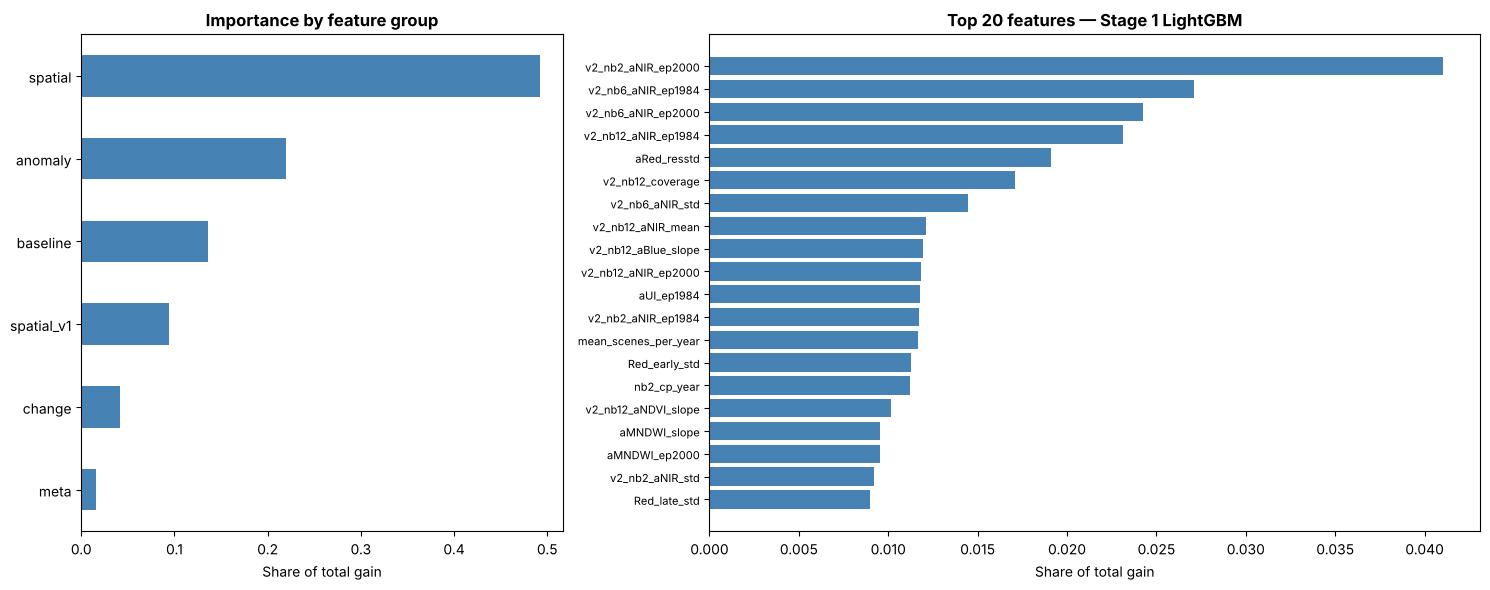

spatial       0.492
anomaly       0.220
baseline      0.136
spatial_v1    0.094
change        0.041
meta          0.016


In [7]:
t0 = time.time()
stage1 = lgb.LGBMClassifier(**STAGE1_PARAMS).fit(X_madrid, y_madrid)
stage1.booster_.save_model(str(MODEL_DIR / 'stage1_madrid_lgbm.txt'))
json.dump({'feature_cols': FEATURE_COLS, 'feature_groups': FEATURE_GROUPS, 'params': STAGE1_PARAMS,
           'classes': stage1.classes_.tolist(), 'standardisation': 'per-city median/IQR, clip ±10',
           'smoothing': {'alpha': SMOOTH_ALPHA, 'r': SMOOTH_R}},
          open(MODEL_DIR / 'stage1_madrid_meta.json', 'w'), indent=1, default=str)
print(f'Stage 1 model trained in {time.time()-t0:.0f}s and saved to {MODEL_DIR / "stage1_madrid_lgbm.txt"}')

# ── Feature importance by group (gain) ────────────────────────────────────────
gain = pd.Series(stage1.booster_.feature_importance('gain'), index=FEATURE_COLS)
gain = gain / gain.sum()
grp_of = {c: g for g in FEATURE_GROUPS for c in groups[g]}
by_group = gain.groupby(gain.index.map(grp_of)).sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.6]})
by_group.plot.barh(ax=axes[0], color='steelblue'); axes[0].set_xlabel('Share of total gain')
axes[0].set_title('Importance by feature group', fontweight='bold')
top = gain.sort_values(ascending=False).head(20)[::-1]
axes[1].barh(range(20), top.values, color='steelblue'); axes[1].set_yticks(range(20))
axes[1].set_yticklabels(top.index, fontsize=8); axes[1].set_xlabel('Share of total gain')
axes[1].set_title('Top 20 features — Stage 1 LightGBM', fontweight='bold')
plt.tight_layout(); plt.savefig(OUT_DIR / 'feature_importance.png', bbox_inches='tight'); plt.show()
print(by_group[::-1].round(3).to_string())

---

## 6.6 Zero-Shot Transfer to Amsterdam

The Madrid model applied to Amsterdam with **no Amsterdam labels** — the size of the remaining domain gap.

In [8]:
raw_ams   = stage1.predict(X_amsterdam, raw_score=True)          # Madrid log-odds for every Amsterdam pixel
proba_ams = stage1.predict_proba(X_amsterdam)
f1_zero   = f1_score(y_amsterdam, stage1.classes_[proba_ams.argmax(1)], average='macro')
f1_zero_s = f1_score(y_amsterdam, stage1.classes_[smooth_proba(pix_ams, proba_ams, SMOOTH_ALPHA, SMOOTH_R).argmax(1)], average='macro')
print(f'Zero-shot macro F1: {f1_zero:.4f} (raw), {f1_zero_s:.4f} (smoothed)   vs Notebook 4: {BASELINE_NB4["zero_shot"]:.4f}')
print('Zero-shot classification report (Madrid model, no Amsterdam labels):')
rep_zero = report_table(y_amsterdam, stage1.classes_[proba_ams.argmax(1)], CLASS_LABELS_AMSTERDAM)
display(rep_zero.style.format({'precision': '{:.4f}', 'recall': '{:.4f}', 'f1-score': '{:.4f}', 'support': '{:,}'}, na_rep=''))

Zero-shot macro F1: 0.4856 (raw), 0.4856 (smoothed)   vs Notebook 4: 0.3427
Zero-shot classification report (Madrid model, no Amsterdam labels):


,precision,recall,f1-score,support
C1 Pre-1945,0.5852,0.1683,0.2615,"7,568"
C2 1945-1984,0.4847,0.6196,0.5439,"8,802"
C3 1984-2004,0.5854,0.5801,0.5828,"6,745"
C4 2004-2024,0.4127,0.8432,0.5542,"2,877"
accuracy,,,0.5027,"25,992"
macro avg,0.5170,0.5528,0.4856,"25,992"
weighted avg,0.5321,0.5027,0.4729,"25,992"


Zero-shot performance improves a lot over Notebook 4, but a clear gap to Madrid remains: the class 1/2 boundary is a
**different year** in each city (1960 vs 1945), so no model can get it right without seeing local labels. That is what the
few-shot step is for.

---

## 6.7 Stage 2: The Transfer Procedure (`adapt_to_city`)

**Deliverable 2.** Given the Stage 1 model and *n* labelled pixels per class from a new city, return class probabilities for
every pixel of that city. Three learners are averaged; each fixes a different weakness:

| Learner | What it does | Why | Best when |
|---------|--------------|-----|-----------|
| **Continued boosting** | New shallow trees (7 leaves, strong L2) are grown on the support set, **starting from the Madrid model's log-odds** (`init_score`). Number of rounds = 20 + 3·n. | Keeps everything Madrid learned and only learns the *correction* for the new city — classic fine-tuning, done with trees. | n ≥ 50 |
| **Regularised stacker** | Multinomial logistic regression on [Madrid log-probabilities + the 40 most important standardised features]. C = 0.05 / 0.1 / 0.3 as n grows. | Few parameters, so it can recalibrate class boundaries from very few labels without overfitting. | n ≤ 50 |
| **Prototypes** | Class means of the 40 top features; softmax over negative distance (Notebook 4's metric-learning approach). Weight = max(0, 1 − n/100). | Lowest-variance learner of all — vital at 5 shots, but its simple linear boundaries cap accuracy, so it fades out by n = 100. | n ≤ 25 |

The function can smooth the average spatially with the α, r chosen on Madrid. Madrid CV selected **α = 0**, so the final
procedure applies **no smoothing**; the option is kept in the code for other cities and is documented in Section 6.4.

**Evidence for these choices** (Amsterdam, 5-fold × 2-repeat, see `solution/exp2_transfer.py`, `exp4_tuning.py`):
every component alone is beaten by the ensemble at n ≤ 50; continued boosting alone is marginally best at n ≥ 100 but
within one standard deviation of the ensemble, so we keep **one procedure for all n** rather than tune a different method per
budget (which would overfit our own evaluation). Self-training on confident unlabelled Amsterdam pixels was also tested and
gave no gain beyond noise, so it was left out.

In [9]:
def _softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)

TOP_FEATS = np.argsort(stage1.booster_.feature_importance('gain'))[::-1][:40]   # chosen on Madrid only

def adapt_to_city(stage1, X_city, pix_city, support_idx, y_support, n, seed=SEED,
                  smooth=(None, None), return_parts=False):
    '''
    Adapt the Madrid Stage 1 model to a new city.

    stage1       : fitted LGBMClassifier (Madrid)
    X_city       : (N, F) features of ALL pixels of the new city, standardised with city_standardise()
    pix_city     : (N, 2) px_key, py_key of those pixels (for spatial smoothing)
    support_idx  : indices (into X_city) of the labelled pixels
    y_support    : their age classes (1-4)
    n            : labelled pixels per class (sets regularisation and boosting length)
    return_parts : if True, also return each learner's own probabilities (used in Section 6.8b)
    returns      : (N, 4) class probabilities for every pixel of the city
    '''
    alpha, r = (SMOOTH_ALPHA, SMOOTH_R) if smooth[0] is None else smooth
    classes = np.array([1, 2, 3, 4])
    raw = stage1.predict(X_city, raw_score=True)          # Madrid prior (log-odds)
    lp  = np.log(_softmax(raw) + 1e-6)
    Z   = X_city[:, TOP_FEATS]

    # (i) continued boosting on top of the Madrid log-odds
    bp = dict(objective='multiclass', num_class=4, learning_rate=0.05, num_leaves=7,
              min_data_in_leaf=max(3, n // 5), feature_fraction=0.5, bagging_fraction=0.8, bagging_freq=1,
              lambda_l2=5.0, verbose=-1, seed=seed, num_threads=2)
    rounds  = int(min(20 + 3 * n, 400))
    dtrain  = lgb.Dataset(X_city[support_idx], y_support - 1, init_score=raw[support_idx].ravel(order='F'))
    booster = lgb.train(bp, dtrain, rounds)
    p_boost = _softmax(raw + booster.predict(X_city, raw_score=True))

    # (ii) regularised logistic stacker on [Madrid log-probs, top features]
    S  = np.hstack([lp, Z]); sc = StandardScaler().fit(S[support_idx])
    C  = 0.05 if n <= 5 else 0.1 if n <= 25 else 0.3
    lr = LogisticRegression(C=C, max_iter=5000).fit(sc.transform(S[support_idx]), y_support)
    p_stack = lr.predict_proba(sc.transform(S))

    # (iii) prototypes, weight fading with n
    protos  = np.stack([Z[support_idx][y_support == c].mean(0) for c in classes])
    d       = np.sqrt(((Z[:, None, :] - protos[None]) ** 2).sum(-1))
    p_proto = _softmax(-d / np.sqrt(Z.shape[1]) * 4)
    w_proto = max(0.0, 1 - n / 100)

    proba = (w_proto * p_proto + p_stack + p_boost) / (w_proto + 2)
    proba = smooth_proba(pix_city, proba, alpha, r)
    if return_parts:
        # each learner on its own + the final average, so their contributions can be compared
        return {'prototypes': p_proto, 'logistic regression': p_stack, 'warm-start boosting': p_boost,
                'ensemble (final)': proba}
    return proba

# ── Example: one Amsterdam model with n = 25 labelled pixels per class ─────────
N_PER_CLASS = 25
rng = np.random.default_rng(SEED)
sup = np.concatenate([rng.choice(np.where(y_amsterdam == c)[0], N_PER_CLASS, replace=False) for c in (1, 2, 3, 4)])
p_example = adapt_to_city(stage1, X_amsterdam, pix_ams, sup, y_amsterdam[sup], N_PER_CLASS)
sup_example = sup
rest = np.setdiff1d(np.arange(len(y_amsterdam)), sup)
print(f'Example n={N_PER_CLASS}: macro F1 on the other {len(rest):,} Amsterdam pixels = '
      f'{f1_score(y_amsterdam[rest], p_example[rest].argmax(1) + 1, average="macro"):.4f}')

Example n=25: macro F1 on the other 25,892 Amsterdam pixels = 0.6785


---

## 6.8 Cross-Validated Few-Shot Evaluation on Amsterdam

**Protocol.** For each budget *n*: 5-fold stratified split of Amsterdam, repeated twice with different seeds (10 scores).
The held-out fold is the test set; the *n* labelled pixels per class are drawn (seeded) **only from the other four folds**, so a
test pixel is never in the support set. Mean ± std over the 10 scores is reported. Notebook 4 used random support/query splits;
the fold-based version guarantees disjoint test sets and is directly comparable to the Madrid CV.

In [10]:
def fewshot_splits(y, n, n_folds=AMS_FOLDS, n_repeats=AMS_REPEATS, seed=SEED):
    rng = np.random.default_rng(seed)
    for rep in range(n_repeats):
        skf = StratifiedKFold(n_folds, shuffle=True, random_state=seed + rep)
        for tr, te in skf.split(np.zeros(len(y)), y):
            sup = np.concatenate([rng.choice(tr[y[tr] == c], n, replace=False) for c in (1, 2, 3, 4)])
            yield sup, te

ams_scores, ams_cm, ams_pool = {}, {}, {}       # ams_pool[n] = (y_true, y_pred) pooled over all test folds
t0 = time.time()
for n in SHOTS_PER_CLASS:
    scores, yt, yp = [], [], []
    for sup, te in fewshot_splits(y_amsterdam, n):
        p = adapt_to_city(stage1, X_amsterdam, pix_ams, sup, y_amsterdam[sup], n)
        pred = p[te].argmax(1) + 1
        scores.append(f1_score(y_amsterdam[te], pred, average='macro'))
        yt.extend(y_amsterdam[te]); yp.extend(pred)
    ams_scores[n] = scores; ams_pool[n] = (np.array(yt), np.array(yp))
    cm = confusion_matrix(yt, yp, labels=[1, 2, 3, 4]); ams_cm[n] = cm / cm.sum(1, keepdims=True)
    b = BASELINE_NB4[n]
    print(f'  n = {n:3d}/class: macro F1 = {np.mean(scores):.4f} +/- {np.std(scores):.4f}   '
          f'(Notebook 4 prototype: {b[0]:.4f} +/- {b[1]:.4f})   [{time.time()-t0:.0f}s]')

  n =   5/class: macro F1 = 0.6451 +/- 0.0253   (Notebook 4 prototype: 0.5437 +/- 0.0324)   [49s]


  n =  25/class: macro F1 = 0.6969 +/- 0.0137   (Notebook 4 prototype: 0.5986 +/- 0.0176)   [101s]


  n =  50/class: macro F1 = 0.7097 +/- 0.0134   (Notebook 4 prototype: 0.6079 +/- 0.0101)   [155s]


  n = 100/class: macro F1 = 0.7404 +/- 0.0099   (Notebook 4 prototype: 0.6129 +/- 0.0097)   [219s]


  n = 200/class: macro F1 = 0.7551 +/- 0.0073   (Notebook 4 prototype: 0.6150 +/- 0.0036)   [292s]


### Results table (deliverable for the presentation)

In [11]:
rows = [{'Model': 'Madrid (Stage 1, 5x5 CV)', 'n per class': 'all', 'Macro F1 mean': madrid_f1_mean,
         'Macro F1 std': madrid_f1_std, 'Notebook 4 baseline': BASELINE_NB4['madrid'][0]}]
for n in SHOTS_PER_CLASS:
    rows.append({'Model': f'Amsterdam (Stage 2)', 'n per class': n, 'Macro F1 mean': np.mean(ams_scores[n]),
                 'Macro F1 std': np.std(ams_scores[n]), 'Notebook 4 baseline': BASELINE_NB4[n][0]})
results = pd.DataFrame(rows)
results['Gain vs baseline'] = results['Macro F1 mean'] - results['Notebook 4 baseline']
results.to_csv(OUT_DIR / 'results_table.csv', index=False)

ams_means = [np.mean(ams_scores[n]) for n in SHOTS_PER_CLASS]
summary = {'madrid_cv': {'mean': madrid_f1_mean, 'std': madrid_f1_std, 'raw_mean': raw_f1_mean, 'raw_std': raw_f1_std,
                         'confusion_row_proportions': cm_madrid.round(4).tolist()},
           'zero_shot': {'raw': f1_zero, 'smoothed': f1_zero_s},
           'amsterdam': {str(n): {'mean': float(np.mean(ams_scores[n])), 'std': float(np.std(ams_scores[n])),
                                  'scores': [float(s) for s in ams_scores[n]],
                                  'confusion_row_proportions': ams_cm[n].round(4).tolist()} for n in SHOTS_PER_CLASS},
           'prize_metrics': {'average_F1_all_five': float(np.mean(ams_means)),
                             'peak_F1': float(np.max(ams_means)),
                             'low_data_F1_n25': float(np.mean(ams_scores[25]))},
           'smoothing': {'alpha': SMOOTH_ALPHA, 'r': SMOOTH_R}, 'seed': SEED}
json.dump(summary, open(OUT_DIR / 'results_summary.json', 'w'), indent=1)

print(results.round(4).to_string(index=False))
print('\nPrize metrics:', {k: round(v, 4) for k, v in summary['prize_metrics'].items()})

                   Model n per class  Macro F1 mean  Macro F1 std  Notebook 4 baseline  Gain vs baseline
Madrid (Stage 1, 5x5 CV)         all         0.7832        0.0035               0.6180            0.1652
     Amsterdam (Stage 2)           5         0.6451        0.0253               0.5437            0.1014
     Amsterdam (Stage 2)          25         0.6969        0.0137               0.5986            0.0983
     Amsterdam (Stage 2)          50         0.7097        0.0134               0.6079            0.1018
     Amsterdam (Stage 2)         100         0.7404        0.0099               0.6129            0.1275
     Amsterdam (Stage 2)         200         0.7551        0.0073               0.6150            0.1401

Prize metrics: {'average_F1_all_five': 0.7094, 'peak_F1': 0.7551, 'low_data_F1_n25': 0.6969}


### F1 vs. log2(sample size)

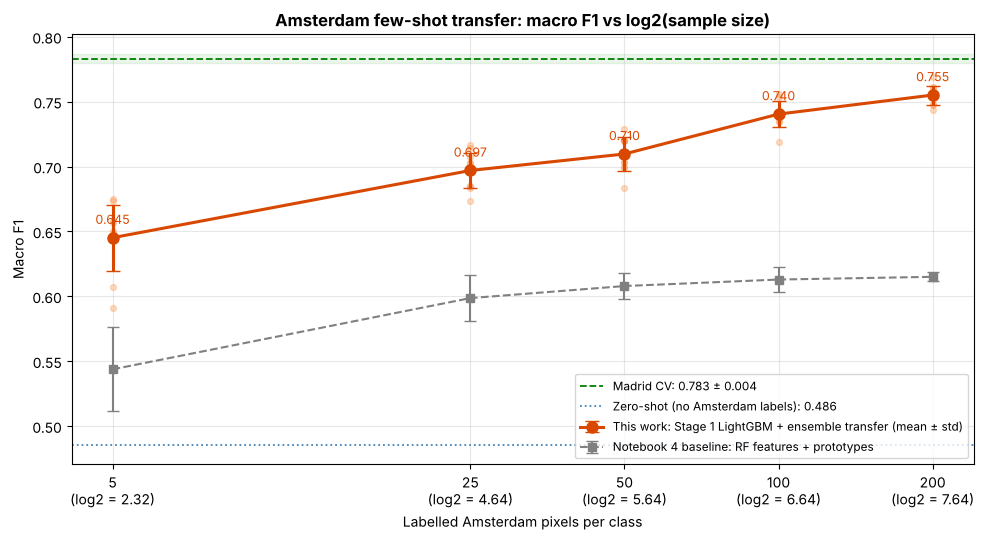

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ns  = np.array(SHOTS_PER_CLASS); lx = np.log2(ns)
m   = np.array([np.mean(ams_scores[n]) for n in ns]); s = np.array([np.std(ams_scores[n]) for n in ns])
bm  = np.array([BASELINE_NB4[n][0] for n in ns]);     bs = np.array([BASELINE_NB4[n][1] for n in ns])

for x, n in zip(lx, ns):
    ax.scatter([x] * len(ams_scores[n]), ams_scores[n], color='#fd8d3c', alpha=0.3, s=18, zorder=2)
ax.errorbar(lx, m, yerr=s, fmt='o-', color='#d94801', lw=2.2, ms=8, capsize=5, zorder=3,
            label='This work: Stage 1 LightGBM + ensemble transfer (mean ± std)')
ax.errorbar(lx, bm, yerr=bs, fmt='s--', color='grey', lw=1.5, ms=6, capsize=4,
            label='Notebook 4 baseline: RF features + prototypes')
ax.axhline(madrid_f1_mean, color='green', ls='--', lw=1.3, label=f'Madrid CV: {madrid_f1_mean:.3f} ± {madrid_f1_std:.3f}')
ax.axhspan(madrid_f1_mean - madrid_f1_std, madrid_f1_mean + madrid_f1_std, color='green', alpha=0.08)
ax.axhline(f1_zero_s, color='steelblue', ls=':', lw=1.3, label=f'Zero-shot (no Amsterdam labels): {f1_zero_s:.3f}')
for x, v in zip(lx, m):
    ax.annotate(f'{v:.3f}', (x, v), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9, color='#d94801')
ax.set_xticks(lx); ax.set_xticklabels([f'{n}\n(log2 = {x:.2f})' for n, x in zip(ns, lx)])
ax.set_xlabel('Labelled Amsterdam pixels per class'); ax.set_ylabel('Macro F1')
ax.set_title('Amsterdam few-shot transfer: macro F1 vs log2(sample size)', fontweight='bold')
ax.grid(alpha=0.3); ax.legend(fontsize=8.5, loc='lower right')
plt.tight_layout(); plt.savefig(OUT_DIR / 'f1_vs_log2n.png', bbox_inches='tight', dpi=150); plt.show()

### Confusion matrices at 25 and 200 labels per class

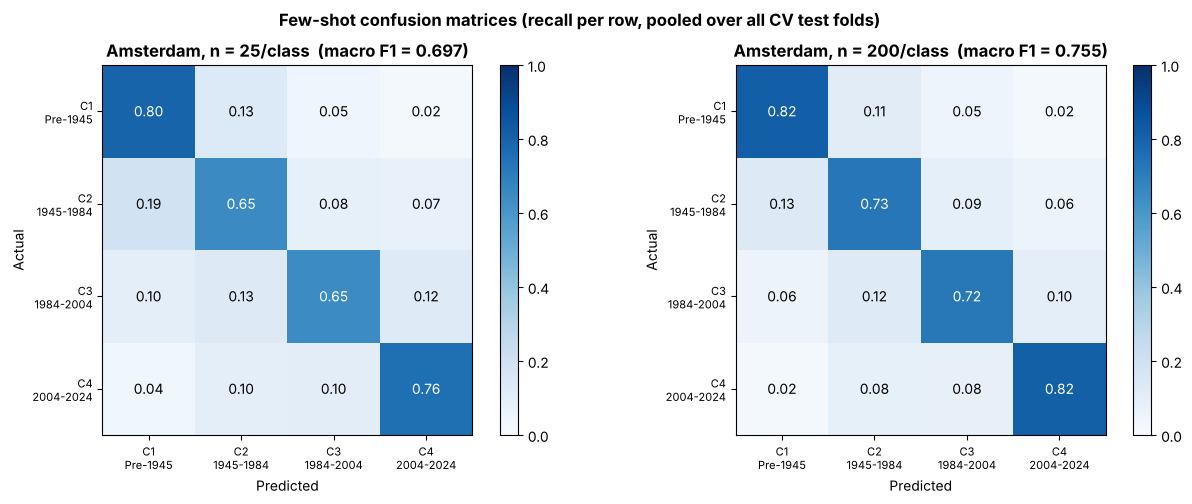

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
xl = [f'C{c}\n{CLASS_LABELS_AMSTERDAM[c]}' for c in (1, 2, 3, 4)]
for ax, n in zip(axes, [25, 200]):
    cmn = ams_cm[n]
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(xl, fontsize=8); ax.set_yticks(range(4)); ax.set_yticklabels(xl, fontsize=8)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', color='white' if cmn[i, j] > 0.6 else 'black')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); plt.colorbar(im, ax=ax)
    ax.set_title(f'Amsterdam, n = {n}/class  (macro F1 = {np.mean(ams_scores[n]):.3f})', fontweight='bold')
plt.suptitle('Few-shot confusion matrices (recall per row, pooled over all CV test folds)', fontweight='bold')
plt.tight_layout(); plt.savefig(OUT_DIR / 'amsterdam_confusion.png', bbox_inches='tight'); plt.show()

### Classification reports of the improved model at every label budget

One full `classification_report` per budget. Each pools the predictions of all 10 CV test folds
(every Amsterdam pixel is a test pixel twice), so the support column is twice the city size.
Precision answers "when the model says class *k*, how often is it right?"; recall answers "of the real class-*k*
buildings, how many did it find?"; F1 is their harmonic mean, and **macro F1** (the challenge metric) is the plain
average of the four class F1 scores.

In [14]:
fmt = {'precision': '{:.4f}', 'recall': '{:.4f}', 'f1-score': '{:.4f}', 'support': '{:,}'}
ams_reports = {}
for n in SHOTS_PER_CLASS:
    ams_reports[n] = report_table(*ams_pool[n], CLASS_LABELS_AMSTERDAM)
    print(f'\n=== Amsterdam, improved model, n = {n} labelled pixels per class '
          f'(macro F1 per fold: {np.mean(ams_scores[n]):.4f} ± {np.std(ams_scores[n]):.4f}) ===')
    display(ams_reports[n].style.format(fmt, na_rep=''))


=== Amsterdam, improved model, n = 5 labelled pixels per class (macro F1 per fold: 0.6451 ± 0.0253) ===


,precision,recall,f1-score,support
C1 Pre-1945,0.6898,0.7379,0.7131,"15,136"
C2 1945-1984,0.6726,0.5712,0.6178,"17,604"
C3 1984-2004,0.6958,0.5980,0.6432,"13,490"
C4 2004-2024,0.4955,0.7965,0.6109,"5,754"
accuracy,,,0.6516,"51,984"
macro avg,0.6384,0.6759,0.6463,"51,984"
weighted avg,0.6640,0.6516,0.6514,"51,984"



=== Amsterdam, improved model, n = 25 labelled pixels per class (macro F1 per fold: 0.6969 ± 0.0137) ===


,precision,recall,f1-score,support
C1 Pre-1945,0.7113,0.7990,0.7526,"15,136"
C2 1945-1984,0.7224,0.6518,0.6853,"17,604"
C3 1984-2004,0.7602,0.6466,0.6988,"13,490"
C4 2004-2024,0.5718,0.7577,0.6518,"5,754"
accuracy,,,0.7050,"51,984"
macro avg,0.6914,0.7138,0.6971,"51,984"
weighted avg,0.7123,0.7050,0.7047,"51,984"



=== Amsterdam, improved model, n = 50 labelled pixels per class (macro F1 per fold: 0.7097 ± 0.0134) ===


,precision,recall,f1-score,support
C1 Pre-1945,0.7481,0.7947,0.7707,"15,136"
C2 1945-1984,0.7345,0.6646,0.6978,"17,604"
C3 1984-2004,0.7437,0.6757,0.7081,"13,490"
C4 2004-2024,0.5770,0.7744,0.6613,"5,754"
accuracy,,,0.7175,"51,984"
macro avg,0.7008,0.7273,0.7095,"51,984"
weighted avg,0.7234,0.7175,0.7176,"51,984"



=== Amsterdam, improved model, n = 100 labelled pixels per class (macro F1 per fold: 0.7404 ± 0.0099) ===


,precision,recall,f1-score,support
C1 Pre-1945,0.7779,0.8121,0.7946,"15,136"
C2 1945-1984,0.7578,0.7072,0.7316,"17,604"
C3 1984-2004,0.7652,0.7053,0.7340,"13,490"
C4 2004-2024,0.6261,0.7965,0.7011,"5,754"
accuracy,,,0.7471,"51,984"
macro avg,0.7317,0.7553,0.7403,"51,984"
weighted avg,0.7510,0.7471,0.7472,"51,984"



=== Amsterdam, improved model, n = 200 labelled pixels per class (macro F1 per fold: 0.7551 ± 0.0073) ===


,precision,recall,f1-score,support
C1 Pre-1945,0.7966,0.8182,0.8073,"15,136"
C2 1945-1984,0.7685,0.7252,0.7462,"17,604"
C3 1984-2004,0.7804,0.7219,0.7500,"13,490"
C4 2004-2024,0.6389,0.8156,0.7165,"5,754"
accuracy,,,0.7614,"51,984"
macro avg,0.7461,0.7702,0.7550,"51,984"
weighted avg,0.7654,0.7614,0.7617,"51,984"


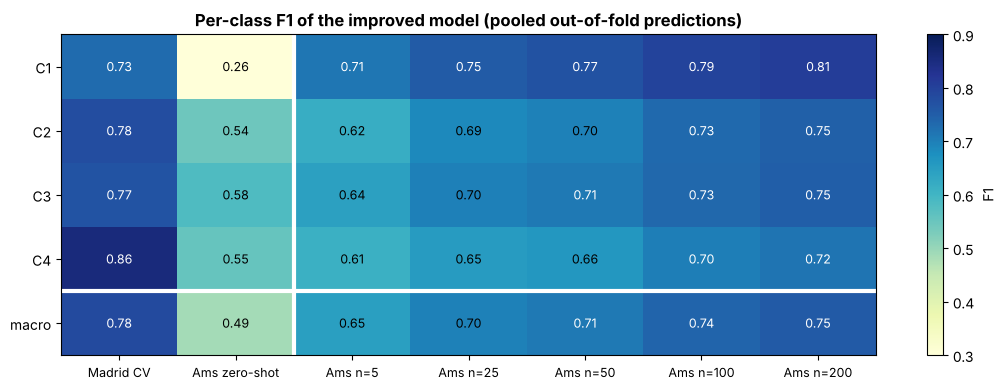

In [15]:
# ── One table + heatmap: per-class F1 of every evaluation, side by side ──────────
cls_rows = [f'C{c}' for c in (1, 2, 3, 4)]
def class_f1(rep):
    return [rep.iloc[i]['f1-score'] for i in range(4)] + [rep.loc['macro avg', 'f1-score']]

per_class = pd.DataFrame({'Madrid CV': class_f1(rep_madrid), 'Ams zero-shot': class_f1(rep_zero),
                          **{f'Ams n={n}': class_f1(ams_reports[n]) for n in SHOTS_PER_CLASS}},
                         index=cls_rows + ['macro'])
per_class.to_csv(OUT_DIR / 'per_class_f1.csv')

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(per_class.values, cmap='YlGnBu', vmin=0.3, vmax=0.9, aspect='auto')
ax.set_xticks(range(per_class.shape[1])); ax.set_xticklabels(per_class.columns, fontsize=9)
ax.set_yticks(range(per_class.shape[0])); ax.set_yticklabels(per_class.index)
ax.axhline(3.5, color='white', lw=3); ax.axvline(1.5, color='white', lw=3)
for i in range(per_class.shape[0]):
    for j in range(per_class.shape[1]):
        v = per_class.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9, color='white' if v > 0.7 else 'black')
plt.colorbar(im, ax=ax, label='F1')
ax.set_title('Per-class F1 of the improved model (pooled out-of-fold predictions)', fontweight='bold')
plt.tight_layout(); plt.savefig(OUT_DIR / 'per_class_f1.png', bbox_inches='tight', dpi=150); plt.show()

**Reading the heatmap.** Each column is one evaluation, each row one class; the last row is macro F1 computed on the
pooled predictions (it can differ slightly from the per-fold mean in the results table). Zero-shot fails mainly
on the classes whose definition differs between cities (class 1/2 cut at 1945 vs 1960). A few labels per class fix
most of that (class 1 F1 rises from 0.26 zero-shot to 0.71 with only 5 labels per class). From 5 to 200 labels every class
then gains roughly 0.10-0.13 F1. Class 4 stays lowest because it is the smallest class in Amsterdam (11% of pixels), so
the model over-predicts it slightly: its recall is high (about 0.8) but its precision is lower (0.50-0.64).

---

### Maps: where the improved model is right and wrong

Predictions placed back on the city grid (north up). For Madrid we use the first CV repeat, where every pixel is
predicted exactly once by a model that never saw it. For Amsterdam we show zero-shot (no labels) and the n = 25
example from Section 6.7 (support pixels outlined in black on the error map).

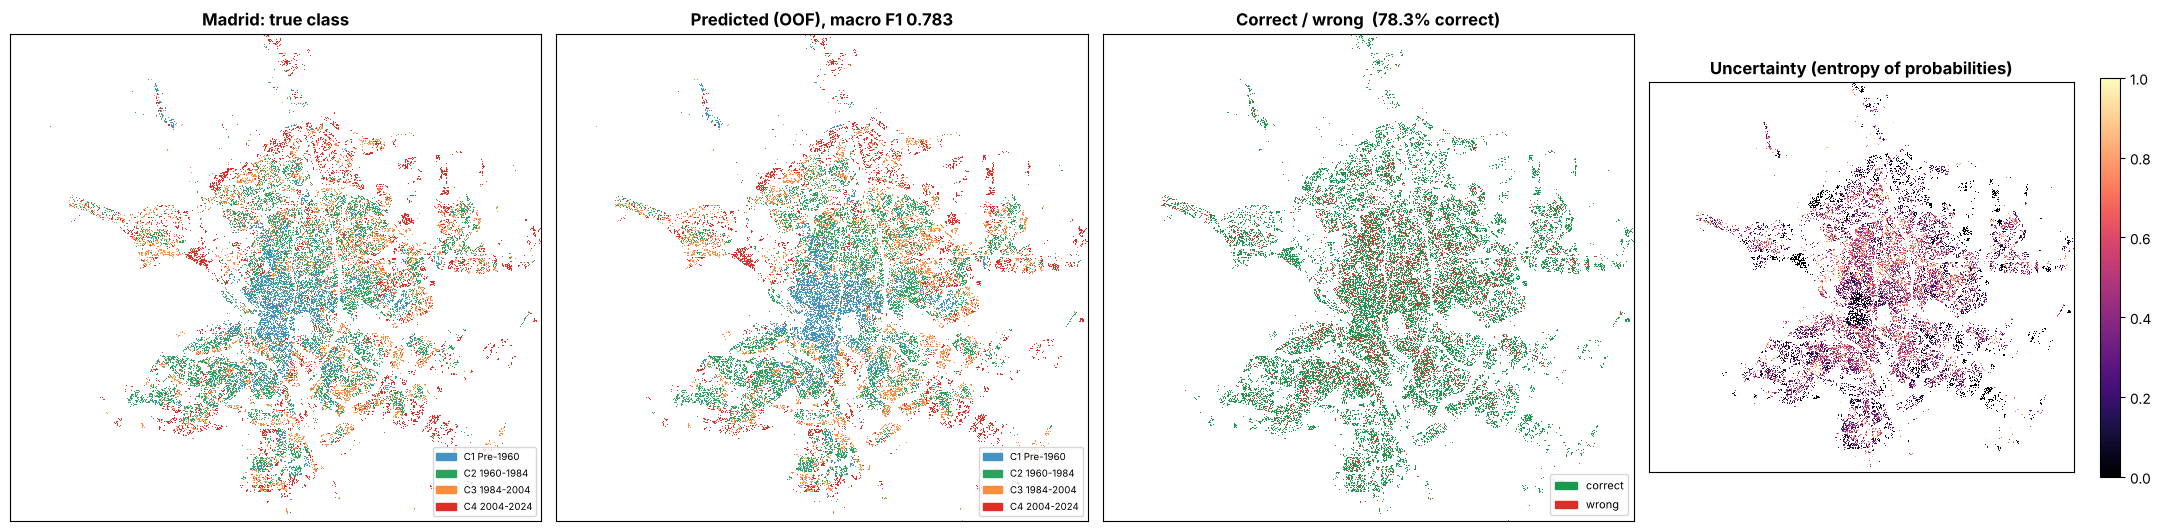

Madrid accuracy by uncertainty quintile (are the uncertain pixels the wrong ones?)
lowest     0.987
low        0.927
mid        0.823
high       0.658
highest    0.521


In [16]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
cls_cmap = ListedColormap([CLASS_COLORS[k] for k in (1, 2, 3, 4)])
cls_norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], 4)
err_cmap = ListedColormap(['#1a9850', '#d73027'])                 # green = correct, red = wrong

def entropy(p):
    return -(p * np.log(np.clip(p, 1e-9, 1))).sum(1) / np.log(4)     # 0 = certain, 1 = uniform

def show_cls(ax, pix, v, title, labels):
    ax.imshow(to_grid(pix, v), cmap=cls_cmap, norm=cls_norm, origin='lower', interpolation='nearest')
    ax.set_title(title, fontweight='bold'); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(handles=[Patch(color=CLASS_COLORS[k], label=f'C{k} {labels[k]}') for k in (1, 2, 3, 4)],
              loc='lower right', fontsize=7)

def show_err(ax, pix, ok, title):
    ax.imshow(to_grid(pix, (~ok).astype(float)), cmap=err_cmap, vmin=0, vmax=1, origin='lower', interpolation='nearest')
    ax.set_title(title, fontweight='bold'); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(handles=[Patch(color='#1a9850', label='correct'), Patch(color='#d73027', label='wrong')],
              loc='lower right', fontsize=8)

# ── Madrid (out-of-fold, repeat 1) ─────────────────────────────────────────────
pred_m = oof1_proba.argmax(1) + 1
ok_m   = pred_m == y_madrid
fig, axes = plt.subplots(1, 4, figsize=(22, 6))
show_cls(axes[0], pix_mad, y_madrid, 'Madrid: true class', CLASS_LABELS_MADRID)
show_cls(axes[1], pix_mad, pred_m, f'Predicted (OOF), macro F1 {f1_score(y_madrid, pred_m, average="macro"):.3f}',
         CLASS_LABELS_MADRID)
show_err(axes[2], pix_mad, ok_m, f'Correct / wrong  ({ok_m.mean():.1%} correct)')
im = axes[3].imshow(to_grid(pix_mad, entropy(oof1_proba)), cmap='magma', vmin=0, vmax=1, origin='lower',
                    interpolation='nearest')
axes[3].set_title('Uncertainty (entropy of probabilities)', fontweight='bold'); axes[3].set_xticks([]); axes[3].set_yticks([])
plt.colorbar(im, ax=axes[3], shrink=0.7)
plt.tight_layout(); plt.savefig(OUT_DIR / 'map_madrid.png', bbox_inches='tight', dpi=120); plt.show()

ent = entropy(oof1_proba)
q = pd.qcut(ent, 5, labels=['lowest', 'low', 'mid', 'high', 'highest'])
print('Madrid accuracy by uncertainty quintile (are the uncertain pixels the wrong ones?)')
print(pd.Series(ok_m).groupby(q, observed=True).mean().round(3).to_string())

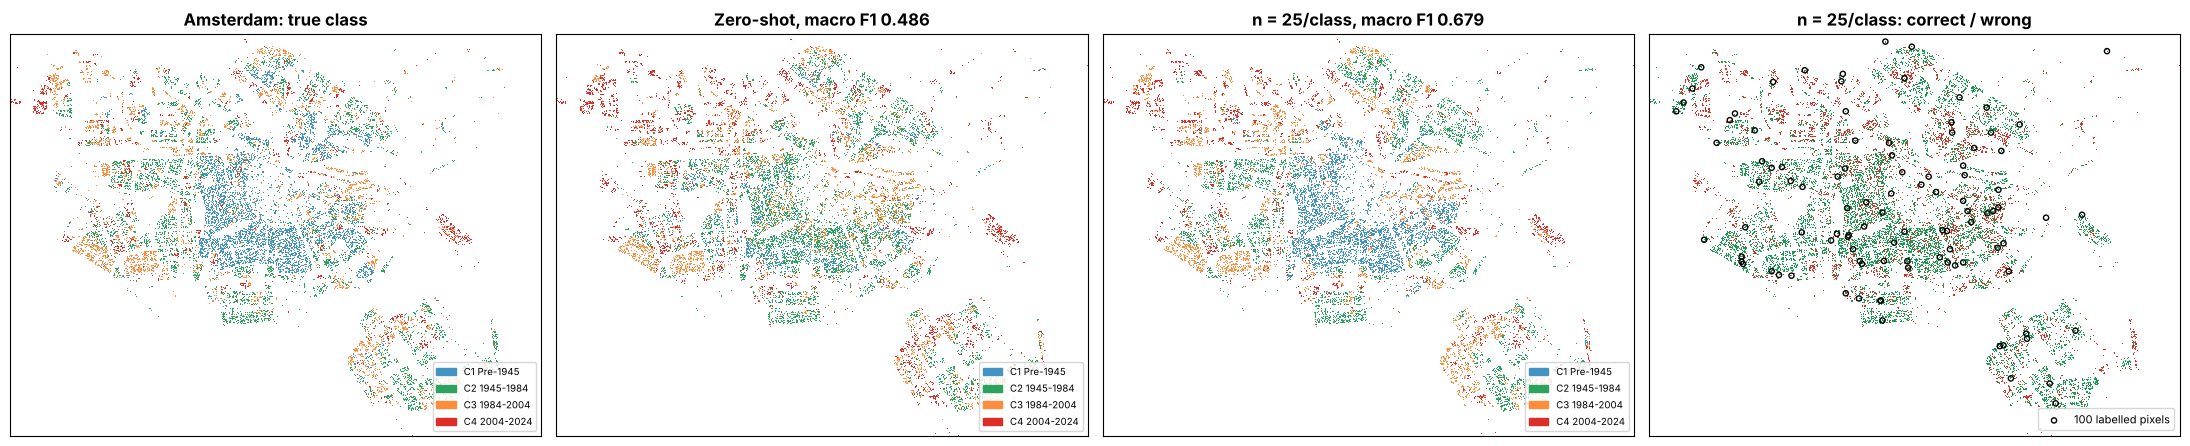

              zero-shot recall  n=25 recall  change
C1 Pre-1945              0.168        0.723   0.555
C2 1945-1984             0.619        0.611  -0.009
C3 1984-2004             0.580        0.709   0.129
C4 2004-2024             0.843        0.777  -0.066


In [17]:
# ── Amsterdam: zero-shot vs 25 labels per class ───────────────────────────────
pred_z = stage1.classes_[proba_ams.argmax(1)]
pred_e = p_example.argmax(1) + 1
mask   = np.ones(len(y_amsterdam), bool); mask[sup_example] = False   # score on non-support pixels
fig, axes = plt.subplots(1, 4, figsize=(22, 6))
show_cls(axes[0], pix_ams, y_amsterdam, 'Amsterdam: true class', CLASS_LABELS_AMSTERDAM)
show_cls(axes[1], pix_ams, pred_z, f'Zero-shot, macro F1 {f1_score(y_amsterdam, pred_z, average="macro"):.3f}',
         CLASS_LABELS_AMSTERDAM)
show_cls(axes[2], pix_ams, pred_e, f'n = 25/class, macro F1 '
         f'{f1_score(y_amsterdam[mask], pred_e[mask], average="macro"):.3f}', CLASS_LABELS_AMSTERDAM)
show_err(axes[3], pix_ams, pred_e == y_amsterdam, 'n = 25/class: correct / wrong')
x0, y0 = pix_ams[:, 0].min(), pix_ams[:, 1].min()
axes[3].scatter(pix_ams[sup_example, 0] - x0, pix_ams[sup_example, 1] - y0, s=14, facecolors='none',
                edgecolors='black', lw=1, label='100 labelled pixels')
axes[3].legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / 'map_amsterdam.png', bbox_inches='tight', dpi=120); plt.show()

# Which classes did the 25 labels fix? (zero-shot vs n = 25 recall, same non-support pixels)
fix = pd.DataFrame({'zero-shot recall': [(pred_z[mask & (y_amsterdam == c)] == c).mean() for c in (1, 2, 3, 4)],
                    'n=25 recall':      [(pred_e[mask & (y_amsterdam == c)] == c).mean() for c in (1, 2, 3, 4)]},
                   index=[f'C{c} {CLASS_LABELS_AMSTERDAM[c]}' for c in (1, 2, 3, 4)])
fix['change'] = fix['n=25 recall'] - fix['zero-shot recall']
print(fix.round(3).to_string())

**Reading the maps.** Errors are not scattered at random: they sit along the borders between estates of different
eras and in mixed areas, where a 30 m pixel covers buildings of more than one age. The uncertainty map lights up in
the same places, and the quintile table confirms that the least certain pixels are the ones most often wrong, so
the probabilities are meaningful. In Amsterdam the zero-shot map confuses the old centre's classes, because the
class 1/2 line sits at 1945 rather than 1960; with 25 labels per class most of the old centre is assigned correctly.

---

## 6.8b Where logistic regression fits: each learner on its own

`adapt_to_city()` (Section 6.7) averages three learners. **Logistic regression is learner (ii)**: an L2-regularised
multinomial `LogisticRegression` fitted on the *n* labelled Amsterdam pixels. Its inputs are the Madrid model's four
log-probabilities plus the 40 most important standardised features. Its regularisation strength `C` grows with *n*
(0.05 / 0.1 / 0.3), because a model with few settings is hard to overfit with 20 labels.

To show what each learner contributes, we re-run the exact same CV splits as Section 6.8, but score every learner on
its own as well as the final average. `adapt_to_city(..., return_parts=True)` returns all four probability sets from
one call, so the comparison is like-for-like.

In [18]:
COMPONENTS = ['prototypes', 'logistic regression', 'warm-start boosting', 'ensemble (final)']
comp_scores = {k: {n: [] for n in SHOTS_PER_CLASS} for k in COMPONENTS}

t0 = time.time()
for n in SHOTS_PER_CLASS:
    for sup, te in fewshot_splits(y_amsterdam, n):          # identical splits to Section 6.8 (same seed)
        parts = adapt_to_city(stage1, X_amsterdam, pix_ams, sup, y_amsterdam[sup], n, return_parts=True)
        for k, p in parts.items():
            comp_scores[k][n].append(f1_score(y_amsterdam[te], p[te].argmax(1) + 1, average='macro'))
    print(f'  n = {n:3d}: ' + '  '.join(f'{k} {np.mean(comp_scores[k][n]):.3f}' for k in COMPONENTS)
          + f'   [{time.time()-t0:.0f}s]')

# ── Results table (printed + saved) ───────────────────────────────────────────
comp_mean = pd.DataFrame({k: [np.mean(comp_scores[k][n]) for n in SHOTS_PER_CLASS] for k in COMPONENTS},
                         index=pd.Index(SHOTS_PER_CLASS, name='labels per class'))
comp_std  = pd.DataFrame({k: [np.std(comp_scores[k][n]) for n in SHOTS_PER_CLASS] for k in COMPONENTS},
                         index=comp_mean.index)
comp_table = comp_mean.round(3).astype(str) + ' ± ' + comp_std.round(3).astype(str)
comp_table['best single learner'] = comp_mean[COMPONENTS[:3]].idxmax(axis=1)
comp_table.to_csv(OUT_DIR / 'transfer_components.csv')
print('\nMacro F1 on Amsterdam test folds (mean ± std over 10 CV scores):\n')
print(comp_table.to_string())

  n =   5: prototypes 0.597  logistic regression 0.595  warm-start boosting 0.551  ensemble (final) 0.645   [49s]


  n =  25: prototypes 0.640  logistic regression 0.680  warm-start boosting 0.676  ensemble (final) 0.697   [100s]


  n =  50: prototypes 0.648  logistic regression 0.690  warm-start boosting 0.702  ensemble (final) 0.710   [154s]


  n = 100: prototypes 0.657  logistic regression 0.711  warm-start boosting 0.737  ensemble (final) 0.740   [218s]


  n = 200: prototypes 0.655  logistic regression 0.728  warm-start boosting 0.754  ensemble (final) 0.755   [291s]

Macro F1 on Amsterdam test folds (mean ± std over 10 CV scores):

                     prototypes logistic regression warm-start boosting ensemble (final)  best single learner
labels per class                                                                                             
5                  0.597 ± 0.04       0.595 ± 0.037       0.551 ± 0.011    0.645 ± 0.025           prototypes
25                 0.64 ± 0.016        0.68 ± 0.016       0.676 ± 0.017    0.697 ± 0.014  logistic regression
50                0.648 ± 0.006        0.69 ± 0.013       0.702 ± 0.015     0.71 ± 0.013  warm-start boosting
100               0.657 ± 0.008       0.711 ± 0.008        0.737 ± 0.01      0.74 ± 0.01  warm-start boosting
200               0.655 ± 0.007       0.728 ± 0.007       0.754 ± 0.006    0.755 ± 0.007  warm-start boosting


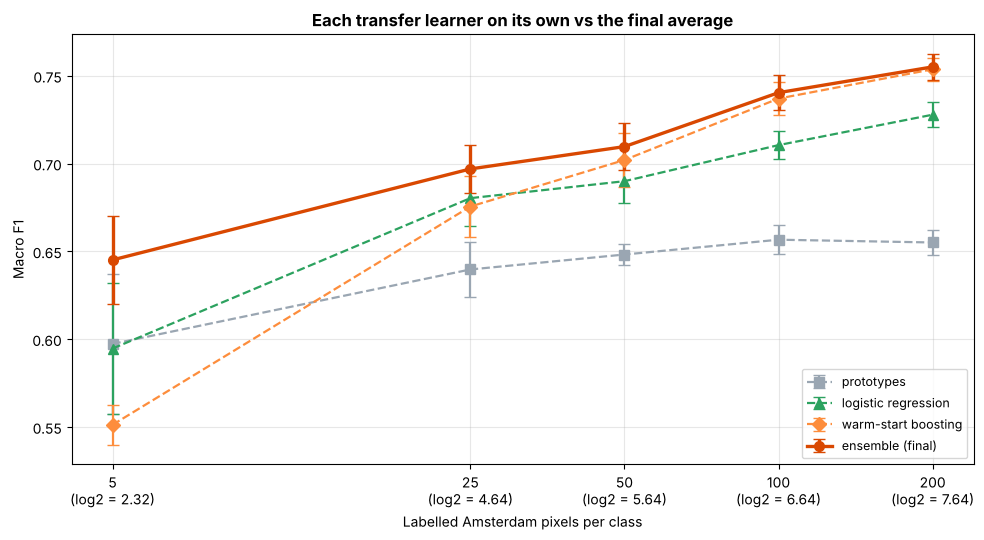

In [19]:
# ── Plot: each learner vs log2(sample size) ───────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5.5))
style = {'prototypes': ('#9aa6b2', 's', '--'), 'logistic regression': ('#2ca25f', '^', '--'),
         'warm-start boosting': ('#fd8d3c', 'D', '--'), 'ensemble (final)': ('#d94801', 'o', '-')}
lx = np.log2(SHOTS_PER_CLASS)
for k in COMPONENTS:
    c, m, ls = style[k]
    ax.errorbar(lx, comp_mean[k], yerr=comp_std[k], color=c, marker=m, ls=ls, lw=2.4 if k.startswith('ensemble') else 1.6,
                ms=7, capsize=4, label=k)
ax.set_xticks(lx); ax.set_xticklabels([f'{n}\n(log2 = {x:.2f})' for n, x in zip(SHOTS_PER_CLASS, lx)])
ax.set_xlabel('Labelled Amsterdam pixels per class'); ax.set_ylabel('Macro F1')
ax.set_title('Each transfer learner on its own vs the final average', fontweight='bold')
ax.grid(alpha=0.3); ax.legend(fontsize=9, loc='lower right')
plt.tight_layout(); plt.savefig(OUT_DIR / 'transfer_components.png', bbox_inches='tight', dpi=150); plt.show()

In [20]:
# ── Inside the logistic regression: what does it rely on? (one example fit, n = 25) ──
n = 25
rng = np.random.default_rng(SEED)
sup = np.concatenate([rng.choice(np.where(y_amsterdam == c)[0], n, replace=False) for c in (1, 2, 3, 4)])
raw = stage1.predict(X_amsterdam, raw_score=True)
S   = np.hstack([np.log(_softmax(raw) + 1e-6), X_amsterdam[:, TOP_FEATS]])     # same inputs as in adapt_to_city
sc  = StandardScaler().fit(S[sup])
lr  = LogisticRegression(C=0.1, max_iter=5000).fit(sc.transform(S[sup]), y_amsterdam[sup])

names = [f'Madrid log-prob, class {c}' for c in (1, 2, 3, 4)] + [FEATURE_COLS[i] for i in TOP_FEATS]
coef  = pd.DataFrame(lr.coef_.T, index=names, columns=[f'class {c}' for c in lr.classes_])
weight = coef.abs().mean(axis=1).sort_values(ascending=False)       # average |coefficient| over the 4 classes
share_madrid = weight[weight.index.str.startswith('Madrid')].sum() / weight.sum()

print(f'Logistic regression, n = {n}: {len(names)} inputs (4 Madrid log-probabilities + 40 features), C = 0.1')
print(f'Share of total |coefficient| on the 4 Madrid log-probabilities: {share_madrid:.1%} '
      f'(vs {4 / len(names):.1%} if all inputs were equal)\n')
print('Ten strongest inputs (mean |coefficient| over the four classes):')
print(weight.head(10).round(3).to_string())

Logistic regression, n = 25: 44 inputs (4 Madrid log-probabilities + 40 features), C = 0.1
Share of total |coefficient| on the 4 Madrid log-probabilities: 14.4% (vs 9.1% if all inputs were equal)

Ten strongest inputs (mean |coefficient| over the four classes):
Madrid log-prob, class 4    0.225
Red_early_std               0.224
nb2_cp_year                 0.196
aRed_resstd                 0.182
v2_nb12_density             0.165
v2_nb2_aNIR_ep2000          0.161
Madrid log-prob, class 2    0.161
Madrid log-prob, class 3    0.151
nb6_density                 0.142
Red_late_std                0.129


**Reading the results above.**

* **No single learner is best everywhere.** Prototypes are the best single learner at 5 labels (0.597), logistic regression at 25 (0.680), and warm-start boosting from 50 upwards (0.702 → 0.754).
* **The average beats every learner at every budget.** The gain over the best single learner is largest when labels are scarce (+0.048 at 5, +0.017 at 25) and shrinks to +0.001 at 200, where boosting dominates. That is why all three are kept under one fixed rule.
* **Why logistic regression is in the ensemble:** it is the strongest single learner at 25 labels, the low-data prize budget, and together with the prototypes it carries the ensemble when labels are scarce.
* **Why it is not used alone:** at 200 labels it trails warm-start boosting by 0.026, and the average beats it at every budget.
* **What it relies on:** about 14% of its weight sits on the four Madrid log-probabilities, against 9% if all 44 inputs were equal. It leans on Madrid's opinion about 1.6× more than on an average feature. Its strongest input is Madrid's class-4 probability. It also weights local features, such as the neighbourhood change-point year (`nb2_cp_year`) and the variability of red reflectance. These let it redraw the class boundaries for Amsterdam, for example the 1945 rather than 1960 cut between classes 1 and 2.

---

## 6.9 Summary

* **Stage 1 (Madrid):** LightGBM on 284 transferable features, per-city standardisation and class balancing, scored with
  5 × 5 repeated CV against Notebook 4's 0.618. Prediction smoothing was tested and rejected on Madrid.
* **Stage 2 (Amsterdam):** `adapt_to_city()` averages warm-start boosting from the Madrid log-odds, a regularised logistic
  regression and fading prototypes. It improves on the Notebook 4 prototype baseline by +0.10 to +0.14 at every label
  budget, and Section 6.8b shows why all three learners are kept.
* **Honest scores:** these use random CV folds, as the challenge notebooks do. On whole unseen 2 km districts
  (Notebook 7, Section 7.6), Madrid scores 0.634 and the Amsterdam average 0.688, still +0.046 and +0.108 above
  the baseline under the same test. See the technical report's leakage audit.
* **Classification reports** for Madrid, zero-shot and every Amsterdam budget are in Sections 6.4, 6.6 and 6.8, with
  the per-class F1 heatmap and prediction/error maps.
* **Saved:** `models/stage1_madrid_lgbm.txt` (+ `stage1_madrid_meta.json`), `results/results_table.csv`,
  `results/results_summary.json`, `results/per_class_f1.csv`, and figures (incl. maps) in `results/`.

Every design decision is tested on its own in **Notebook 7 (Decision Evidence & Leakage Audit)**.

See `REPORT` (research report) for the full write-up, ablations, abstract and the 300-word justification.